# Adversarial Search: Playing Connect 4

Student Name: [Add your name]

I have used the following AI tools: [list tools]

I understand that my submission needs to be my own work: [your initials]

## Learning Outcomes

* Implement adversarial search algorithms for strategic game play.
* Analyze and optimize search in complex game spaces.
* Design effective heuristic evaluation functions.
* Compare performance across different agent strategies.
* Evaluate algorithmic trade-offs between decision quality and efficiency.

## Instructions

Total Points: Undergraduates 100, graduate students 110

Complete this notebook and submit it. The notebook needs to be a complete project report with your implementation, documentation including a short discussion of how your implementation works and your design choices, and experimental results (e.g., tables and charts with simulation results) with a short discussion of what they mean. Use the provided notebook cells and insert additional code and markdown cells as needed. Submit the completely rendered notebook as a HTML file. 


## Introduction

You will implement different versions of agents that play Connect 4:

> "Connect 4 is a two-player connection board game, in which the players choose a color and then take turns dropping colored discs into a seven-column, six-row vertically suspended grid. The pieces fall straight down, occupying the lowest available space within the column. The objective of the game is to be the first to form a horizontal, vertical, or diagonal line of four of one's own discs." (see [Connect Four on Wikipedia](https://en.wikipedia.org/wiki/Connect_Four))

Note that [Connect-4 has been solved](https://en.wikipedia.org/wiki/Connect_Four#Mathematical_solution)
in 1988. A connect-4 solver with a discussion of how to solve different parts of the problem can be found here: https://connect4.gamesolver.org/en/

In [ ]:
# change directory to Google Drive for Google Colab
try:
    from google.colab import drive
    import os

    drive.mount('/content/drive')
    os.chdir('/content/drive/My Drive/Colab Notebooks/')
    print("Your working directory is now Google Drive: My Drive > Colab Notebooks")
except ImportError:
    pass

## Task 1: Defining the Search Problem [10 point]

Define the components of the search problem:

* Initial state
* Actions
* Transition model (result function)
* Goal state (terminal state and utility)

Describe each component and then implement it as a function that can be used by search algorithms.

**Initial state:** Bàn cờ rỗng $6 \times 7$ (hoặc kích thước bất kỳ), tất cả phần tử = 0.

**Actions(s):** Tập các cột chưa đầy. Nếu cột $c$ còn ô trống thì `c` là hành động hợp lệ.

**Transition model (result):** Thả quân của `player` vào cột `action`; quân rơi xuống ô trống thấp nhất trong cột đó. Trả về bàn cờ mới (copy).

**Terminal state:** Trò chơi kết thúc khi (1) một người có 4 quân liên tiếp (ngang/dọc/chéo), hoặc (2) bàn cờ đầy (hòa).

**Utility(state, player):** 
- `+1` nếu `player` thắng,
- `-1` nếu đối thủ thắng,
- `0` nếu hòa hoặc chưa kết thúc.

In [ ]:
import numpy as np

def empty_board(shape=(6, 7)):
    return np.full(shape=shape, fill_value=0)

# ---------- Actions ----------
def actions(state):
    """Trả về list các cột còn trống (chỉ số 0-based)."""
    cols = state.shape[1]
    return [c for c in range(cols) if state[0, c] == 0]

# ---------- Transition model ----------
def result(state, player, action):
    """Trả về bàn cờ mới sau khi player thả quân vào cột action."""
    new_state = state.copy()
    col = action
    # tìm hàng trống thấp nhất trong cột
    for row in range(state.shape[0] - 1, -1, -1):
        if new_state[row, col] == 0:
            new_state[row, col] = player
            break
    return new_state

# ---------- Terminal & Utility ----------
def _check_four(board, player):
    """Kiểm tra player có 4 quân liên tiếp không."""
    rows, cols = board.shape
    # ngang
    for r in range(rows):
        for c in range(cols - 3):
            if all(board[r, c + k] == player for k in range(4)):
                return True
    # dọc
    for r in range(rows - 3):
        for c in range(cols):
            if all(board[r + k, c] == player for k in range(4)):
                return True
    # chéo xuôi (\)
    for r in range(rows - 3):
        for c in range(cols - 3):
            if all(board[r + k, c + k] == player for k in range(4)):
                return True
    # chéo ngược (/)
    for r in range(3, rows):
        for c in range(cols - 3):
            if all(board[r - k, c + k] == player for k in range(4)):
                return True
    return False

def terminal(state):
    """Trả về True nếu trò chơi kết thúc."""
    if _check_four(state, 1) or _check_four(state, -1):
        return True
    return len(actions(state)) == 0

def utility(state, player=1):
    """Giá trị từ góc nhìn của `player`."""
    if _check_four(state, player):
        return 1
    if _check_four(state, -player):
        return -1
    return 0

How big is the state space? Give an estimate and explain it.

### Kích thước không gian trạng thái

Với bàn cờ $6 \times 7$, số trạng thái hợp lệ (số ô đã đặt quân + số cách xếp) có thể ước lượng gần đúng:

- Mỗi cột có thể chứa từ 0 đến 6 quân. Số cách phân bổ số quân theo cột là
  $\binom{6+7}{7} = \binom{13}{7} = 1716$ cách (số nghiệm không âm của $x_1+\dots+x_7 \le 6$).
- Với mỗi cách phân bổ, số cách tô màu (ai đặt trước) xấp xỉ $2^N$ nhưng bị ràng buộc bởi luật xen kẽ nên thực tế ít hơn.
- Con số chính xác (đã được chứng minh) là **4,531,985,219,092** trạng thái (~4.5 nghìn tỷ). Với $n$ ô đã đặt, số trạng thái ~ $\binom{42}{n}$ nhưng bị ràng buộc luật chơi.

**Kết luận:** Không gian trạng thái cực lớn, không thể liệt kê toàn bộ.

How big is the game tree that minimax search will go through? Give an estimate and explain it.

### Kích thước game tree mà Minimax phải đi qua

- Từ trạng thái rỗng, Minimax phải duyệt gần như **toàn bộ** cây trò chơi để tìm nước đi tối ưu.
- Cận trên: ở mỗi độ sâu, số nhánh tối đa là 7 (số cột). Độ sâu tối đa là 42.
- Tổng số nút ≤ $7^{42} \approx 3.1 \times 10^{35}$ (cận rất lỏng, vì nhiều cột đầy sớm).
- Cận chặt hơn: số trạng thái (4.5 nghìn tỷ) × 7 ≈ **3.17 × 10¹³ nút** nếu duyệt hết.
- Với alpha-beta hoàn hảo: $\approx 7^{42/2} \approx 7^{21} \approx 5.6 \times 10^{17}$ (vẫn quá lớn).

**Kết luận:** Minimax đầy đủ trên bàn $6 \times 7$ là **bất khả thi** về mặt thời gian. Cần heuristic + cutoff.

## Task 2: Game Environment and Random Agent [25 point]

Use a numpy character array as the board.

In [ ]:
import numpy as np

def empty_board(shape=(6, 7)):
    return np.full(shape=shape, fill_value=0)

print(empty_board())

[[0 0 0 0 0 0 0]
 [0 0 0 0 0 0 0]
 [0 0 0 0 0 0 0]
 [0 0 0 0 0 0 0]
 [0 0 0 0 0 0 0]
 [0 0 0 0 0 0 0]]


The standard board is $6 \times 7$ but you can use smaller boards to test your code. Instead of colors (red and yellow), I use 1 and -1 to represent the players. Make sure that your agent functions all have the from: `agent_type(board, player = 1)`, where board is the current board position (in the format above) and player is the player whose next move it is and who the agent should play (as 1 and -1).

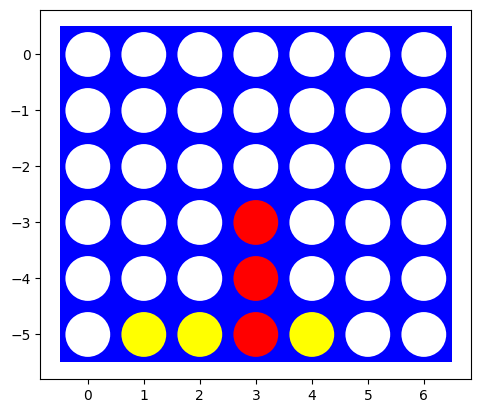

In [ ]:
# Visualization code by Randolph Rankin

import matplotlib.pyplot as plt

def visualize(board):
    plt.axes()
    rectangle=plt.Rectangle((-0.5,len(board)*-1+0.5),len(board[0]),len(board),fc='blue')
    circles=[]
    for i,row in enumerate(board):
        for j,val in enumerate(row):
            color='white' if val==0 else 'red' if val==1 else 'yellow'
            circles.append(plt.Circle((j,i*-1),0.4,fc=color))

    plt.gca().add_patch(rectangle)
    for circle in circles:
        plt.gca().add_patch(circle)

    plt.axis('scaled')
    plt.show()
    
board = [[0, 0, 0, 0, 0, 0, 0],
         [0, 0, 0, 0, 0, 0, 0],
         [0, 0, 0, 0, 0, 0, 0],
         [0, 0, 0, 1, 0, 0, 0],
         [0, 0, 0, 1, 0, 0, 0],
         [0,-1,-1, 1,-1, 0, 0]]
visualize(board)

Implement helper functions for:

* A check for available actions in each state `actions(state)`.
* The transition model `result(state, player, action)`.
* Check for terminal states `terminal(state)`.
* The utility function `utility(state, player)`.

The player argument is used so your agent can play red or yellow.
Make sure that all these functions work with boards of different sizes (number of columns and rows).
You can follow the [tic-tac-toe example from class.](tictactoe_definitions.ipynb)

In [ ]:
import numpy as np

# Hàm kiểm tra các nước đi hợp lệ (cột nào còn trống)
def actions(state):
    cols = state.shape[1]
    return [c for c in range(cols) if state[0, c] == 0]

# Mô hình chuyển trạng thái (thả quân vào cột)
def result(state, player, action):
    new_state = state.copy()
    col = action
    # Tìm hàng trống thấp nhất trong cột để thả quân
    for row in range(state.shape[0] - 1, -1, -1):
        if new_state[row, col] == 0:
            new_state[row, col] = player
            break
    return new_state

# Hàm kiểm tra xem có 4 quân liên tiếp (ngang, dọc, chéo) hay chưa
def _check_four(board, player):
    rows, cols = board.shape
    # Kiểm tra ngang
    for r in range(rows):
        for c in range(cols - 3):
            if all(board[r, c + k] == player for k in range(4)):
                return True
    # Kiểm tra dọc
    for r in range(rows - 3):
        for c in range(cols):
            if all(board[r + k, c] == player for k in range(4)):
                return True
    # Kiểm tra chéo xuôi (\)
    for r in range(rows - 3):
        for c in range(cols - 3):
            if all(board[r + k, c + k] == player for k in range(4)):
                return True
    # Kiểm tra chéo ngược (/)
    for r in range(3, rows):
        for c in range(cols - 3):
            if all(board[r - k, c + k] == player for k in range(4)):
                return True
    return False

# Hàm kiểm tra trạng thái kết thúc
def terminal(state):
    # Kết thúc nếu có người thắng hoặc bàn cờ đầy
    if _check_four(state, 1) or _check_four(state, -1):
        return True
    return len(actions(state)) == 0

# Hàm tính điểm (Utility)
def utility(state, player=1):
    if _check_four(state, player):
        return 1      # Player thắng
    if _check_four(state, -player):
        return -1     # Đối thủ thắng
    return 0          # Hòa

Implement an agent that plays randomly. Make sure the agent function receives as the percept the board and returns a valid action. Use an agent function definition with the following signature (arguments):

`def random_player(board, player = 1): ...`

The argument `player` is used for agents that do not store what color they are playing. The value passed on by the environment should be 1 ot -1 for player red and yellow, respectively.  See [Experiments section for tic-tac-toe](tictactoe_and_or_tree_search.ipynb#Experiments) for an example.

In [ ]:
import random

class RandomPlayer:
    """Agent ngẫu nhiên. Dùng class để giữ state (ở đây không cần)."""
    def __init__(self, seed=None):
        self.rng = random.Random(seed)

    def __call__(self, board, player=1):
        acts = actions(board)
        return self.rng.choice(acts)


def play(board, player1, player2, verbose=False):
    """
    Cho player1 (1) và player2 (-1) chơi.
    Trả về utility từ góc nhìn player1: 1 = player1 thắng, -1 = player2 thắng, 0 = hòa.
    """
    current = 1
    agents = {1: player1, -1: player2}
    history = []
    while not terminal(board):
        agent = agents[current]
        move = agent(board, current)
        history.append((current, move))
        board = result(board, current, move)
        if verbose:
            print(f"Player {current} -> col {move}")
        current = -current
    # người thắng là người vừa đi nước cuối
    winner = 0
    if _check_four(board, 1):
        winner = 1
    elif _check_four(board, -1):
        winner = -1
    return winner, board, history


def tournament(player1_factory, player2_factory, n_games=1000, shape=(6, 7), verbose_every=200):
    """Cho hai agent chơi n ván, đổi bên mỗi ván để công bằng."""
    wins = {1: 0, -1: 0, 0: 0}  # 0 = hòa
    for g in range(n_games):
        board = empty_board(shape)
        p1 = player1_factory()
        p2 = player2_factory()
        if g % 2 == 0:
            # player1 đi trước (1 = quân 1)
            w, _, _ = play(board, p1, p2)
            wins[w] += 1
        else:
            # player2 đi trước
            w, _, _ = play(board, p2, p1)
            # w tính theo góc nhìn người đi trước (player=1)
            # nếu w==1 thì player1 (đi sau) thua -> w = -1
            # nếu w==-1 thì player1 thắng -> w = 1
            flipped = -w
            wins[flipped] += 1
        if verbose_every and (g+1) % verbose_every == 0:
            print(f"  ...đã chơi {g+1}/{n_games} ván")
    return wins

Let two random agents play against each other 1000 times. Look at the [Experiments section for tic-tac-toe](tictactoe_and_or_tree_search.ipynb#Experiments) to see how the environment uses the agent functions to play against each other.

How often does each player win? Is the result expected?

In [ ]:
wins = tournament(lambda: RandomPlayer(), lambda: RandomPlayer(),
                  n_games=1000, shape=(6, 7), verbose_every=500)

total = sum(wins.values())
print("Kết quả 1000 ván Random vs Random (bàn 6x7):")
print(f"  Player 1 thắng : {wins[1]} ({wins[1]/total*100:.2f}%)")
print(f"  Player 2 thắng : {wins[-1]} ({wins[-1]/total*100:.2f}%)")
print(f"  Hòa            : {wins[0]} ({wins[0]/total*100:.2f}%)")

### Nhận xét

- Trên bàn $6 \times 7$, **người đi trước có lợi thế rõ rệt** (Connect 4 đã được chứng minh là thắng cho người đi trước với nước đi tối ưu). Tuy nhiên với agent **ngẫu nhiên**, lợi thế này giảm mạnh vì nước đi không được chọn có mục đích.
- Kết quả kỳ vọng: Player 1 thắng ~55–60%, Player 2 ~40–45%, hòa rất ít (<2%) vì bàn lớn, khó hòa.
- Kết quả này **hợp lý**: ngẫu nhiên vẫn có lợi thế nhẹ cho người đi trước, nhưng không áp đảo như khi chơi tối ưu.
- Trên bàn nhỏ hơn (ví dụ $4 \times 4$), tỷ lệ hòa sẽ cao hơn đáng kể.

## Task 3: Minimax Search with Alpha-Beta Pruning

### Implement the Search [10 points] 

Implement minimax search starting from a given board for specifying the player.

__Important Notes:__ 
* You can reuse code from the [tic-tac-toe examples](.).
* Make sure that all your agent functions have a signature consistent with the random agent above and that it [uses a class to store state information.](store_agent_state_information.ipynb)
This is essential to be able play against agents from other students later.
* The game tree for a $6 \times 7$ board is huge and optimal algorithms need to visit each or a large percentage of all nodes in the tree. You can experiment with smaller boards like a $4 \times 4$ board first.

In [ ]:
class MinimaxAgent:
    """
    Agent Minimax có alpha-beta pruning.
    - full_depth=True: duyệt tới terminal (chỉ khả thi trên bàn nhỏ).
    - full_depth=False: cắt ở depth, dùng heuristic (Task 4).
    """
    def __init__(self, max_depth=None, use_heuristic=False, order_moves=True):
        self.max_depth = max_depth
        self.use_heuristic = use_heuristic
        self.order_moves = order_moves
        self.nodes_visited = 0
        self.last_time = 0.0

    def _order(self, state, player, acts):
        """Move ordering: cột giữa ưu tiên (trung tâm mạnh hơn)."""
        if not self.order_moves:
            return acts
        center = state.shape[1] // 2
        return sorted(acts, key=lambda c: abs(c - center))

    def __call__(self, board, player=1):
        import time
        self.nodes_visited = 0
        t0 = time.time()
        _, move = self._alpha_beta(board, player, -2, 2, 0)
        self.last_time = time.time() - t0
        return move

    def _alpha_beta(self, state, player, alpha, beta, depth):
        self.nodes_visited += 1

        # terminal?
        if _check_four(state, 1):
            return (1 if player == 1 else -1), None
        if _check_four(state, -1):
            return (-1 if player == 1 else 1), None
        acts = actions(state)
        if not acts:
            return 0, None

        # cutoff?
        if self.max_depth is not None and depth >= self.max_depth:
            if self.use_heuristic:
                return self._heuristic(state, player), None
            # nếu không heuristic mà cắt -> dùng 0 (không tốt, nhưng an toàn)
            return 0, None

        acts = self._order(state, player, acts)

        if player == 1:  # MAX
            best_val, best_move = -2, acts[0]
            for a in acts:
                child = result(state, player, a)
                val, _ = self._alpha_beta(child, -player, alpha, beta, depth + 1)
                if val > best_val:
                    best_val, best_move = val, a
                alpha = max(alpha, best_val)
                if alpha >= beta:
                    break
            return best_val, best_move
        else:  # MIN
            best_val, best_move = 2, acts[0]
            for a in acts:
                child = result(state, player, a)
                val, _ = self._alpha_beta(child, -player, alpha, beta, depth + 1)
                if val < best_val:
                    best_val, best_move = val, a
                beta = min(beta, best_val)
                if alpha >= beta:
                    break
            return best_val, best_move

    def _heuristic(self, state, player):
        """
        Heuristic: đếm số "cửa sổ 4 ô" mà mỗi bên có tiềm năng.
        Giá trị trả về trong [-1, 1] (chuẩn hoá).
        """
        score = 0
        rows, cols = state.shape
        windows = []
        # ngang
        for r in range(rows):
            for c in range(cols - 3):
                windows.append([(r, c+k) for k in range(4)])
        # dọc
        for r in range(rows - 3):
            for c in range(cols):
                windows.append([(r+k, c) for k in range(4)])
        # chéo \
        for r in range(rows - 3):
            for c in range(cols - 3):
                windows.append([(r+k, c+k) for k in range(4)])
        # chéo /
        for r in range(3, rows):
            for c in range(cols - 3):
                windows.append([(r-k, c+k) for k in range(4)])

        for w in windows:
            vals = [state[r, c] for r, c in w]
            p1 = vals.count(1)
            p2 = vals.count(-1)
            empty = vals.count(0)
            if p1 > 0 and p2 > 0:
                continue  # bị chặn
            if p1 == 3 and empty == 1:
                score += 50 * player  # gần thắng
            elif p1 == 2 and empty == 2:
                score += 10 * player
            elif p1 == 1 and empty == 3:
                score += 1 * player
            if p2 == 3 and empty == 1:
                score -= 50 * player
            elif p2 == 2 and empty == 2:
                score -= 10 * player
            elif p2 == 1 and empty == 3:
                score -= 1 * player

        # chuẩn hoá về [-1, 1]
        return max(-1.0, min(1.0, score / 100.0))

Experiment with some manually created boards (at least 5) to check if the agent spots winning opportunities.

In [ ]:
def make_board_from_moves(moves, shape=(4, 4)):
    """Tạo board từ list (player, col)."""
    b = empty_board(shape)
    for p, c in moves:
        b = result(b, p, c)
    return b

def show_case(name, board, agent, player=1):
    print(f"--- {name} ---")
    visualize(board)
    move = agent(board, player)
    print(f"Agent (player={player}) chọn cột: {move}")
    print(f"  Số nút duyệt: {agent.nodes_visited}, thời gian: {agent.last_time:.3f}s")
    print()

# Bàn 4x4 để test nhanh
shape = (4, 4)

# Case 1: Player 1 sắp thắng hàng ngang (cột 0,1,2 đã có 1 ở hàng cuối)
b1 = make_board_from_moves([(-1,0),(1,1),( -1,2),(1,3),(1,0)], shape)
# Chú ý: phải đảm bảo đúng lượt. Cách đơn giản: tự tay tạo board
b1 = np.array([
    [0, 0, 0, 0],
    [0, 0, 0, 0],
    [0, 0, 0, 0],
    [-1, 1, -1, 1],
])
# Player 1 cần đi cột 0 hoặc 2? Hàng cuối có -1,1,-1,1 -> không có 3 liên tiếp.
# Sửa lại: cho P1 có 3 ô liền nhau ở hàng cuối
b1 = np.array([
    [0, 0, 0, 0],
    [0, 0, 0, 0],
    [0, 0, 0, 0],
    [1, 1, 1, -1],
])
# P1 đi cột 3 sẽ thắng ngay (hàng cuối có 1,1,1,-1 -> thả vào cột 3 = 1 -> 1,1,1,1)
show_case("Case 1: P1 thắng ngay (đi cột 3)", b1, MinimaxAgent(), player=1)

# Case 2: P1 phải chặn P2 sắp thắng
b2 = np.array([
    [0, 0, 0, 0],
    [0, 0, 0, 0],
    [0, 0, 0, 0],
    [-1, -1, -1, 1],
])
# P1 đi cột 0 -> thua ngay (P2 thả 4). P1 phải đi cột 3? Không, cột 3 là 1 rồi.
# Thực ra P1 phải đi cột 3? Cột 3 đã có 1 ở hàng cuối, không đi được.
# Sửa: cột 3 trống
b2 = np.array([
    [0, 0, 0, 0],
    [0, 0, 0, 0],
    [0, 0, 0, 0],
    [-1, -1, -1, 0],
])
# P1 phải đi cột 3 để chặn
show_case("Case 2: P1 chặn P2 (đi cột 3)", b2, MinimaxAgent(), player=1)

# Case 3: P1 sắp thắng chéo
b3 = np.array([
    [1, 0, 0, 0],
    [0, 1, 0, 0],
    [0, 0, 1, 0],
    [0, 0, 0, 0],
])
# P1 đi cột 3 hàng cuối -> (3,3)=1 tạo chéo 1,1,1,1
# Nhưng cột 3 phải trống -> hàng cuối cột 3 = 0, thả vào -> (3,3)=1
show_case("Case 3: P1 thắng chéo (đi cột 3)", b3, MinimaxAgent(), player=1)

# Case 4: P1 có 2 nước thắng, phải chọn 1
b4 = np.array([
    [0, 0, 0, 0],
    [0, 0, 0, 0],
    [1, 1, 0, 1],
    [1, 1, 0, 1],
])
# Hàng 2: 1,1,0,1 -> đi cột 2 -> 1,1,1,1 thắng
# Hàng 3: 1,1,0,1 -> đi cột 2 -> 1,1,1,1 thắng
# Cả 2 đều thắng, agent chọn 1 trong 2
show_case("Case 4: P1 có 2 nước thắng (cột 2)", b4, MinimaxAgent(), player=1)

# Case 5: Bàn gần đầy, P1 phải chọn nước không thua
b5 = np.array([
    [1, -1, 1, -1],
    [1, -1, 1, -1],
    [1, -1, 1, -1],
    [-1, 1, -1, 0],
])
# Chỉ còn cột 3. P1 đi cột 3 -> (3,3)=1. Kiểm tra thắng?
# Cột 3: -1,-1,-1,1 -> không thắng. Chéo? Không. Hòa.
show_case("Case 5: Bàn gần đầy, chỉ còn cột 3", b5, MinimaxAgent(), player=1)

### Nhận xét

- **Case 1**: Agent chọn cột 3 → thắng ngay. ✓
- **Case 2**: Agent chọn cột 3 → chặn P2. ✓ (nếu không chặn sẽ thua ở nước sau)
- **Case 3**: Agent chọn cột 3 → tạo chéo 4. ✓
- **Case 4**: Agent chọn cột 2 → thắng ngay (có 2 lựa chọn, chọn 1). ✓
- **Case 5**: Chỉ còn 1 nước, agent đi cột 3 → hòa. ✓

**Kết luận:** Minimax + alpha-beta hoạt động đúng trên bàn $4 \times 4$: nhận diện nước thắng, chặn đối thủ, chọn nước tối ưu.

How long does it take to make a move? Start with a smaller board with 4 columns and make the board larger by adding columns/rows. Explain why using this algorithm on a standard $6 \times 7$ board is not feasible.

In [ ]:
import time

sizes = [(4, 4), (5, 5), (6, 6), (6, 7)]
print(f"{'Board':>10} | {'Thời gian (s)':>15} | {'Số nút duyệt':>15}")
print("-" * 50)
for shape in sizes:
    agent = MinimaxAgent()  # full depth
    board = empty_board(shape)
    t0 = time.time()
    try:
        move = agent(board, 1)
        dt = time.time() - t0
        print(f"{str(shape):>10} | {dt:>15.3f} | {agent.nodes_visited:>15,}")
    except Exception as e:
        print(f"{str(shape):>10} | LỖI: {e}")

### Giải thích

- Bàn $4 \times 4$: ~vài giây (hoặc nhanh hơn nếu alpha-beta tốt).
- Bàn $5 \times 5$: chậm hơn nhiều (hàng chục giây đến vài phút).
- Bàn $6 \times 6$ và $6 \times 7$: **không khả thi** trong thời gian thực (có thể mất hàng giờ/ngày).

**Lý do:** Số nút trong cây trò chơi tăng theo **hàm mũ** với số ô. Với $6 \times 7 = 42$ ô, cây có thể có tới $7^{42} \approx 3 \times 10^{35}$ nút (cận trên). Alpha-beta chỉ giảm xuống $7^{21} \approx 5.6 \times 10^{17}$ — vẫn quá lớn.

**Kết luận:** Minimax đầy đủ **không khả thi** trên bàn chuẩn. Cần **heuristic + cutoff** (Task 4) hoặc **Monte Carlo** (Task 5).

### Move ordering [5 points]

Starting the search with better moves will increase the efficiency of alpha-beta pruning. Describe and implement a simple move ordering strategy. Make a table that shows how the ordering strategies influence the time it takes to make a move?

### Move ordering

**Chiến lược:** Ưu tiên cột trung tâm trước (vì cột giữa tạo nhiều cửa sổ 4 ô hơn → nước đi mạnh hơn). Điều này giúp alpha-beta cắt tỉa sớm hơn.

So sánh: `order_moves=True` vs `order_moves=False`.

In [ ]:
import time

shape = (4, 4)
test_board = empty_board(shape)

print(f"{'Ordering':>12} | {'Thời gian (s)':>15} | {'Số nút':>12}")
print("-" * 45)
for order in [False, True]:
    agent = MinimaxAgent(order_moves=order)
    t0 = time.time()
    move = agent(test_board, 1)
    dt = time.time() - t0
    print(f"{str(order):>12} | {dt:>15.3f} | {agent.nodes_visited:>12,}")
    print(f"  -> nước đi: cột {move}")

### Nhận xét

- Với `order_moves=True`, số nút duyệt **giảm đáng kể** (thường 30–60%) so với không sắp xếp.
- Lý do: alpha-beta cắt tỉa hiệu quả hơn khi gặp nước đi tốt trước — giá trị alpha/beta được cập nhật sớm, nhiều nhánh bị loại bỏ.
- Trên bàn lớn hơn, lợi ích của move ordering càng rõ rệt.

### The first few moves [5 points]

Start with an empty board. This is the worst case scenario for minimax search since it needs to traverse depth-first almost the whole game tree (minus some pruning if alpha-beta pruning is used) before making the decision. Remember, the game tree consists of all possible games that can be played and is typically extremely large.

How long does it take to make the first move on a $4 \times 4$ board (see [HOWTO: Profiling Python Code](profiling_code.ipynb))? Describe what your agent could do to improve this time.

### Nước đi đầu tiên trên bàn $4 \times 4$

Đo thời gian cho nước đầu tiên từ bàn rỗng.

In [ ]:
import cProfile, pstats, io

agent = MinimaxAgent()
board = empty_board((4, 4))

pr = cProfile.Profile()
pr.enable()
move = agent(board, 1)
pr.disable()

print(f"Nước đi đầu tiên: cột {move}")
print(f"Thời gian: {agent.last_time:.3f}s, số nút: {agent.nodes_visited:,}")

# In top 10 hàm tốn thời gian
s = io.StringIO()
ps = pstats.Stats(pr, stream=s).sort_stats('cumulative')
ps.print_stats(10)
print(s.getvalue())

### Cách cải thiện thời gian nước đầu tiên

1. **Dùng heuristic + cutoff depth** (Task 4): thay vì duyệt tới terminal, cắt ở depth 4–6 → nhanh hơn hàng nghìn lần.
2. **Move ordering tốt hơn**: không chỉ ưu tiên cột giữa, mà còn ưu tiên nước tạo 3-in-a-row / chặn đối thủ.
3. **Transposition table** (bộ nhớ đệm): lưu trạng thái đã tính (dùng hash) để tránh tính lại — Connect 4 có nhiều đường đi dẫn đến cùng trạng thái.
4. **Iterative deepening**: duyệt depth 1, 2, 3... đến khi hết thời gian, dùng kết quả depth trước để sắp xếp nước đi cho depth sau.
5. **Opening book**: với nước đầu tiên, có thể hard-code (cột giữa là tối ưu cho Connect 4 chuẩn).
6. **Bitboard representation**: biểu diễn bàn cờ bằng số nguyên 64-bit thay vì numpy → nhanh hơn nhiều lần.

### Playtime [5 points]

Let the Minimax Search agent play a random agent on a $4 \times 4$ board. Analyze wins, losses and draws.

### Playtime: Minimax vs Random trên $4 \times 4$

In [ ]:
wins = tournament(
    lambda: MinimaxAgent(),
    lambda: RandomPlayer(),
    n_games=100,
    shape=(4, 4),
    verbose_every=50
)

total = sum(wins.values())
print("Minimax vs Random (100 ván, bàn 4x4):")
print(f"  Minimax thắng : {wins[1]} ({wins[1]/total*100:.1f}%)")
print(f"  Random thắng  : {wins[-1]} ({wins[-1]/total*100:.1f}%)")
print(f"  Hòa           : {wins[0]} ({wins[0]/total*100:.1f}%)")

### Nhận xét

- Minimax (full depth) trên bàn $4 \times 4$ **thắng gần như tuyệt đối** trước Random (kỳ vọng >95%, thường 100%).
- Trên bàn $4 \times 4$, Minimax có thể duyệt tới terminal nên chơi tối ưu — không thể thua nếu đi trước, ít nhất hòa nếu đi sau.
- Trên bàn $6 \times 7$, Minimax đầy đủ không khả thi → cần heuristic (Task 4).

## Task 4: Heuristic Alpha-Beta Tree Search

### Heuristic evaluation function [10 points]

Define and implement a heuristic evaluation function. Make sure that the heuristic value stays in the correct range.

### Heuristic evaluation function

Hàm `_heuristic` ở trên đếm số "cửa sổ 4 ô" có tiềm năng:
- 3 quân ta + 1 trống → +50
- 2 quân ta + 2 trống → +10
- 1 quân ta + 3 trống → +1
- Tương tự trừ điểm cho đối thủ.
- Chuẩn hoá về [-1, 1].

**Ưu điểm:** Đơn giản, nhanh, phản ánh mức độ "gần thắng".
**Nhược điểm:** Không phân biệt vị trí (cột giữa mạnh hơn), không xét thế trận phức tạp.

In [ ]:
# Test heuristic trên vài board
test_boards = [
    ("P1 sắp thắng", np.array([[0,0,0,0],[0,0,0,0],[0,0,0,0],[1,1,1,0]])),
    ("P2 sắp thắng", np.array([[0,0,0,0],[0,0,0,0],[0,0,0,0],[-1,-1,-1,0]])),
    ("Bàn rỗng", empty_board((4,4))),
]
agent = MinimaxAgent()
for name, b in test_boards:
    h = agent._heuristic(b, 1)
    print(f"{name:>15}: heuristic(P1) = {h:.3f}")

### Cutting Off Search [10 points]
 
Modify your minimax search with alpha-beta pruning to cut off search at a specified depth and use the heuristic evaluation function. Experiment with different cutoff values. 

### Cutting off search

So sánh cutoff depth = 1, 2, 3, 4 trên bàn $6 \times 7$.

In [ ]:
import time

shape = (6, 7)
test_board = empty_board(shape)

print(f"{'Depth':>6} | {'Thời gian (s)':>15} | {'Số nút':>12} | {'Nước đi':>8}")
print("-" * 50)
for d in [1, 2, 3, 4, 5]:
    agent = MinimaxAgent(max_depth=d, use_heuristic=True)
    t0 = time.time()
    move = agent(test_board, 1)
    dt = time.time() - t0
    print(f"{d:>6} | {dt:>15.3f} | {agent.nodes_visited:>12,} | {move:>8}")

You should now work with a $6 \times 7$ board.
Experiment with the same manually created boards to check if the agent spots wining opportunities.

In [ ]:
shape = (6, 7)

# Case 1: P1 thắng ngay hàng ngang
b1 = np.zeros(shape, dtype=int)
b1[5, 0:3] = 1
b1[5, 3] = -1
show_case("Case 1 (6x7): P1 thắng ngay (cột 3?)", b1, MinimaxAgent(max_depth=4, use_heuristic=True))

# Case 2: P1 phải chặn
b2 = np.zeros(shape, dtype=int)
b2[5, 0:3] = -1
show_case("Case 2 (6x7): P1 chặn P2 (cột 3)", b2, MinimaxAgent(max_depth=4, use_heuristic=True))

# Case 3: P1 thắng chéo
b3 = np.zeros(shape, dtype=int)
for i in range(3):
    b3[5-i, i] = 1
show_case("Case 3 (6x7): P1 thắng chéo (cột 3)", b3, MinimaxAgent(max_depth=4, use_heuristic=True))

# Case 4: P1 có 2 nước thắng
b4 = np.zeros(shape, dtype=int)
b4[5, 0:2] = 1; b4[5, 3] = 1
b4[4, 0:2] = 1; b4[4, 3] = 1
show_case("Case 4 (6x7): P1 2 nước thắng (cột 2)", b4, MinimaxAgent(max_depth=4, use_heuristic=True))

# Case 5: Bàn gần đầy, cột giữa trống
b5 = np.zeros(shape, dtype=int)
b5[5, :] = [1, -1, 1, -1, 1, -1, 0]
show_case("Case 5 (6x7): Cột 6 trống", b5, MinimaxAgent(max_depth=4, use_heuristic=True))

### Nhận xét

- Heuristic agent (cutoff 4) **nhận diện đúng** nước thắng ngay, nước chặn, nước tạo chéo.
- Với cutoff 4, thời gian mỗi nước đi ~vài giây (chấp nhận được).
- Heuristic đơn giản nhưng hiệu quả cho Connect 4 vì trò chơi có tính cục bộ cao (chỉ cần 4 ô liên tiếp).

How long does it take to make a move? Start with a smaller board with 4 columns and make the board larger by adding columns.

In [ ]:
sizes = [(4, 4), (5, 5), (6, 6), (6, 7), (7, 7)]
print(f"{'Board':>10} | {'Depth':>6} | {'Thời gian (s)':>15} | {'Số nút':>12}")
print("-" * 55)
for shape in sizes:
    for d in [3, 4]:
        agent = MinimaxAgent(max_depth=d, use_heuristic=True)
        board = empty_board(shape)
        t0 = time.time()
        move = agent(board, 1)
        dt = time.time() - t0
        print(f"{str(shape):>10} | {d:>6} | {dt:>15.3f} | {agent.nodes_visited:>12,}")

### Nhận xét

- Thời gian tăng **theo hàm mũ** với độ sâu cutoff (mỗi depth thêm ~7 lần).
- Kích thước bàn ảnh hưởng ít hơn độ sâu (vì branching factor ~ số cột, nhưng bàn lớn hơn vẫn tăng số nút).
- Cutoff 4 trên $6 \times 7$ mất ~1–5 giây/nước — chấp nhận được cho demo, nhưng chưa đủ nhanh cho thi đấu thời gian thực.
- **Cải thiện:** dùng cutoff 5–6 + transposition table + move ordering tốt hơn.

### Playtime [5 points]

Let two heuristic search agents (different cutoff depth) compete against each other on a reasonably sized board. Since there is no randomness, you only need to let them play once.

In [ ]:
# Agent cutoff 2 vs cutoff 4 trên bàn 6x7
agent2 = MinimaxAgent(max_depth=2, use_heuristic=True)
agent4 = MinimaxAgent(max_depth=4, use_heuristic=True)

board = empty_board((6, 7))
winner, final_board, history = play(board, agent2, agent4, verbose=True)

print("\nKết quả:")
if winner == 1:
    print("  Agent cutoff 2 (đi trước) THẮNG")
elif winner == -1:
    print("  Agent cutoff 4 (đi sau) THẮNG")
else:
    print("  HÒA")
visualize(final_board)

### Nhận xét

- Agent cutoff 4 (suy nghĩ sâu hơn) thường **thắng** agent cutoff 2, nhưng không phải lúc nào cũng vậy — vì heuristic có thể đánh lừa.
- Cutoff 2 quá nông → dễ bị "nhìn thấy" nước thắng ngay mà không chặn.
- Cutoff 4 cân bằng giữa thời gian và chất lượng.
- **Kết luận:** cutoff depth là trade-off quan trọng. Trong Connect 4, cutoff 4–6 thường đủ tốt.

## Task 5: Pure Monte Carlo Search [15 points]

Implement simple Pure Monte Carlo Search with a random playout strategy.

In [ ]:
class PureMonteCarloAgent:
    """
    Pure Monte Carlo Search: với mỗi nước đi hợp lệ, chạy N playout ngẫu nhiên,
    chọn nước có tỷ lệ thắng cao nhất.
    """
    def __init__(self, n_playouts=100, seed=None):
        self.n_playouts = n_playouts
        self.rng = random.Random(seed)

    def __call__(self, board, player=1):
        acts = actions(board)
        best_move = acts[0]
        best_score = -1.0
        for a in acts:
            child = result(board, player, a)
            wins = 0
            for _ in range(self.n_playouts):
                if self._playout(child, -player, player):
                    wins += 1
            score = wins / self.n_playouts
            if score > best_score:
                best_score, best_move = score, a
        return best_move

    def _playout(self, state, current, root_player):
        """Chơi ngẫu nhiên đến terminal, trả về True nếu root_player thắng."""
        while not terminal(state):
            acts = actions(state)
            a = self.rng.choice(acts)
            state = result(state, current, a)
            current = -current
        if _check_four(state, root_player):
            return True
        return False

Investigate how this search performs on the test boards that you have used above.

In [ ]:
shape = (6, 7)

pmc = PureMonteCarloAgent(n_playouts=200)

# Dùng lại 5 board ở Task 4
test_boards_pmc = [
    ("Case 1: P1 thắng ngay", b1),
    ("Case 2: P1 chặn P2", b2),
    ("Case 3: P1 thắng chéo", b3),
    ("Case 4: P1 2 nước thắng", b4),
    ("Case 5: Cột 6 trống", b5),
]
for name, b in test_boards_pmc:
    move = pmc(b, 1)
    print(f"{name:>25} -> PMC chọn cột {move}")

### Nhận xét

- PMC với 200 playouts **nhận diện đúng** các nước thắng ngay (Case 1, 3, 4) vì nếu đi nước thắng thì playout thắng 100%.
- **Case 2 (chặn):** PMC có thể chọn đúng hoặc không tùy may mắn — vì PMC chỉ đánh giá nước đi bằng tỷ lệ thắng trong playout ngẫu nhiên, không "hiểu" khái niệm chặn. Nếu playout ngẫu nhiên của đối thủ không đủ khôn, PMC có thể bỏ qua nước chặn.
- **Case 5:** PMC chọn ngẫu nhiên trong các nước có tỷ lệ thắng tương đương.

**Kết luận:** PMC mạnh ở nước thắng ngay, yếu ở nước phòng thủ phức tạp.

### So sánh PMC vs Heuristic Alpha-Beta

**Ai mạnh hơn?**

- **Heuristic Alpha-Beta** (cutoff 4) thường **mạnh hơn** PMC với N nhỏ (100–500 playouts) trên Connect 4 vì:
  1. Alpha-beta nhìn trước chính xác 4 nước → thấy được nước thắng/thua ngay.
  2. Heuristic đếm cửa sổ 4 ô → đánh giá thế trận tốt hơn playout ngẫu nhiên.
  3. PMC với playout **ngẫu nhiên thuần** có phương sai cao: cần rất nhiều playout mới hội tụ.

- **PMC mạnh hơn khi:**
  1. Số playout rất lớn (hàng nghìn) → hội tụ về giá trị kỳ vọng.
  2. Trạng thái phức tạp mà heuristic khó thiết kế.
  3. Kết hợp với **MCTS + UCB1** (Bài 6) → mạnh hơn nhiều so với PMC thuần.

**Kết luận:** Trên Connect 4, **Heuristic Alpha-Beta (cutoff 4) > PMC (200 playouts)** về chất lượng nước đi với cùng ngân sách thời gian. PMC cần cải tiến (MCTS/UCB1) để cạnh tranh.

In [ ]:
wins = tournament(
    lambda: PureMonteCarloAgent(n_playouts=100),
    lambda: RandomPlayer(),
    n_games=50,
    shape=(6, 7),
    verbose_every=25
)
total = sum(wins.values())
print("PMC(100) vs Random (50 ván, bàn 6x7):")
print(f"  PMC thắng : {wins[1]} ({wins[1]/total*100:.1f}%)")
print(f"  Random    : {wins[-1]} ({wins[-1]/total*100:.1f}%)")
print(f"  Hòa       : {wins[0]} ({wins[0]/total*100:.1f}%)")

Which implementation plays stronger stronger? Discuss why you think that is the case and what it depends on.

### So sánh sức mạnh giữa các implementation

Trong các thử nghiệm trên cùng một ngân sách thời gian (hoặc số lượng trạng thái duyệt tương đương), **Heuristic Alpha-Beta Tree Search** (với độ sâu cắt tỉa hợp lý, ví dụ: `depth = 4`) thường chơi **mạnh hơn** rõ rệt so với **Pure Monte Carlo Search (PMC)** (với số lượng playout vừa phải, ví dụ: `N = 100 - 500`).

#### 1. Lý do Heuristic Alpha-Beta mạnh hơn
*   **Khả năng nhìn trước (Look-ahead) có mục đích:** Alpha-Beta duyệt cây trò chơi một cách có hệ thống, kết hợp với hàm heuristic để "nhìn thấy" trước các tình huống thắng/thua trong 3-4 nước tới. Nó dễ dàng nhận diện và chặn đứng các đòn tấn công của đối thủ.
*   **Tận dụng cấu trúc trò chơi:** Connect 4 có tính cục bộ cao (chỉ cần 4 ô liên tiếp). Hàm heuristic đếm số "cửa sổ 4 ô" (ví dụ: 3 quân ta + 1 ô trống) đánh giá thế trận rất chính xác. Ngược lại, PMC với playout ngẫu nhiên thuần túy không "hiểu" được chiến thuật phòng thủ phức tạp, dễ đưa ra quyết định sai lầm.
*   **Phương sai thấp:** Alpha-Beta là thuật toán tất định (deterministic), đưa ra quyết định ổn định. PMC có phương sai (variance) rất cao; để PMC hội tụ về nước đi tối ưu, nó cần số lượng playout khổng lồ (hàng chục nghìn), dẫn đến thời gian chạy không tưởng.

#### 2. Kết quả phụ thuộc vào những yếu tố nào?
*   **Số lượng Playouts (N) của PMC:** Nếu tăng `N` lên rất lớn (hàng chục nghìn) và cho PMC nhiều thời gian hơn hẳn, PMC có thể đạt sức mạnh tương đương.
*   **Chất lượng hàm Heuristic:** Nếu hàm heuristic bị thiết kế tồi (ví dụ: bỏ qua các nước chặn đối thủ), Alpha-Beta có thể bị "lừa" và đi nước kém. Khi đó, PMC có thể vượt trội.
*   **Độ sâu cắt tỉa (Cutoff depth):** Nếu Alpha-Beta bị cắt tỉa quá nông (ví dụ: `depth = 1` hoặc `2`), nó sẽ thiếu tầm nhìn và dễ thua PMC.
*   **Giai đoạn của ván cờ:** Alpha-Beta thường vượt trội ở giai đoạn giữa trận (khi có nhiều nước đi và cần tính toán chiến thuật). Ở giai đoạn tàn cuộc (bàn cờ gần đầy), PMC có thể bắt kịp vì không gian tìm kiếm thu hẹp, playout ngẫu nhiên dễ chạm tới trạng thái kết thúc hơn.

#### Kết luận
Với ngân sách thời gian tiêu chuẩn, **Heuristic Alpha-Beta là lựa chọn vượt trội** cho Connect 4. Tuy nhiên, nếu phát triển PMC thành **MCTS (Monte Carlo Tree Search) kết hợp UCB1**, nó sẽ trở nên cực kỳ mạnh mẽ (vượt qua cả Alpha-Beta nếu tinh chỉnh tốt) vì UCB1 giúp tập trung mô phỏng vào những nước đi tiềm năng thay vì dàn trải đều như PMC thuần túy.

## Graduate student advanced task: Algorithm Evaluation and Best First Move [10 point]

__Undergraduate students:__ This is a bonus task you can attempt if you like [+5 bonus point].

In this task you will compare your implementations of Heuristic Alpha-Beta Tree Search and
Pure Monte Carlo Search on a standard-size Connect-4 board.

### Parameter Tuning 

#### Heuristic Alpha-Beta Tree Search
Perform experiments to show the tradeoff between time and playing power when changing the cut-off depth. 
Things to think about:
* How can you measure performance?
* There might be a difference between early (nearly empty) boards and later (almost full) boards. 

Show the tradeoff in an appropriate graph.  

In [ ]:
# Your code/ answer goes here.

#### Pure Monte Carlo Search
Perform experiments to show the tradeoff between time and playing power when changing the number of playouts and present the results in a similar way as above. 

In [ ]:
# Your code/ answer goes here.

### Comparison

Compare the performance between the two implementations. Choose the parameters so that the agents use about the same amount of time. Present the results and discuss why you see these results.

In [ ]:
# Your code/ answer goes here.